## Exploratory Data Analysis

#### Objective

The objective is to predict the number of shares (popularity) on social media platforms for the news articles using the dataset provided. In your submission, you should evaluate at least 3 suitable models for predicting the number of shares.

#### Overall Evaluation

Once you have identified the most suitable model, find a way to compare the models against each other and explain which of these models is more suitable for the task.

In [1]:
%matplotlib inline
#import modules
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

## Preliminary Data Exploration

In [2]:
#load dataset
df = pd.read_csv('./data/mini_project_1_data.csv')

df.head()

,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
0,0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,monday,593,12.0,219.0,0.663594,1.0,0.815385,...,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,monday,711,9.0,255.0,0.604743,1.0,0.791946,...,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,monday,1500,9.0,211.0,0.575130,1.0,0.663866,...,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,monday,1200,9.0,531.0,0.503788,1.0,0.665635,...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,monday,505,13.0,1072.0,0.415646,1.0,0.540890,...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
df.URL.head(100)

0     http://mashable.com/2013/01/07/amazon-instant-...
1     http://mashable.com/2013/01/07/ap-samsung-spon...
2     http://mashable.com/2013/01/07/apple-40-billio...
3     http://mashable.com/2013/01/07/astronaut-notre...
4      http://mashable.com/2013/01/07/att-u-verse-apps/
                            ...                        
95       http://mashable.com/2013/01/09/ces-2013-comic/
96    http://mashable.com/2013/01/09/ces-2013-show-f...
97    http://mashable.com/2013/01/09/ces-challenge-n...
98    http://mashable.com/2013/01/09/chesapeake-ligh...
99    http://mashable.com/2013/01/09/crowdrise-edwar...
Name: URL, Length: 100, dtype: object

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35680 entries, 0 to 35679
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         35680 non-null  int64  
 1   URL                        35680 non-null  object 
 2   timedelta                  35680 non-null  float64
 3   weekday                    35680 non-null  object 
 4   shares                     35680 non-null  int64  
 5   n_tokens_title             35680 non-null  float64
 6   n_tokens_content           35680 non-null  float64
 7   n_unique_tokens            35680 non-null  float64
 8   n_non_stop_words           35680 non-null  float64
 9   n_non_stop_unique_tokens   35680 non-null  float64
 10  num_hrefs                  34959 non-null  float64
 11  num_self_hrefs             34959 non-null  float64
 12  num_imgs                   34261 non-null  float64
 13  num_videos                 18925 non-null  flo

In [5]:
print(df.nunique())
print()
print("Check Categorical and Boolean Column unique values:")
print(f"{df.weekday.name}:{df.weekday.unique()}")
print(f"{df.n_tokens_title.name}:{df.n_tokens_title.unique()}")
print(f"{df.data_channel.name}:{df.data_channel.unique()}")
print(f"{df.num_keywords.name}:{df.num_keywords.unique()}")


ID                           35680
URL                          35680
timedelta                      724
weekday                          7
shares                        1418
n_tokens_title                  20
n_tokens_content              2324
n_unique_tokens              25197
n_non_stop_words              1429
n_non_stop_unique_tokens     21345
num_hrefs                      128
num_self_hrefs                  57
num_imgs                        89
num_videos                      46
n_comments                     834
average_token_length         27595
data_channel                     6
self_reference_min_shares     1231
self_reference_max_shares     1119
self_reference_avg_shares     7853
num_keywords                    10
kw_min_min                      22
kw_max_min                    1064
kw_avg_min                   15949
kw_min_max                    1006
kw_max_max                      31
kw_avg_max                   28284
kw_min_avg                   14686
kw_max_avg          

In [6]:
df.describe()

,ID,timedelta,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
count,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,34959.000000,34959.000000,...,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000
mean,19823.468918,354.523234,3402.054961,10.395432,545.995123,0.530461,0.970263,0.672738,10.866358,3.282531,...,7.220095,26.169703,1142.296851,310.297441,13533.498851,752318.562220,259143.787814,1115.670961,5637.977838,3130.799667
std,11452.292291,214.301086,11934.878541,2.114600,469.550052,0.136935,0.169862,0.153881,11.260971,3.834065,...,1.909604,69.705812,3844.829034,616.961660,57623.779316,214391.922961,135080.424060,1136.741358,6026.965362,1311.012948
min,0.000000,8.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,-1.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0.000000,0.000000
25%,9890.750000,163.000000,946.000000,9.000000,247.000000,0.471030,1.000000,0.625912,4.000000,1.000000,...,6.000000,-1.000000,445.000000,141.440476,0.000000,843300.000000,172595.650000,0.000000,3559.646658,2379.762290
50%,19801.500000,339.000000,1400.000000,10.000000,410.000000,0.539011,1.000000,0.690323,8.000000,3.000000,...,7.000000,-1.000000,658.000000,235.428571,1400.000000,843300.000000,244133.333333,1020.667532,4348.584651,2867.991456
75%,29788.250000,543.000000,2800.000000,12.000000,716.000000,0.608203,1.000000,0.754036,14.000000,4.000000,...,9.000000,4.000000,1000.000000,357.000000,7800.000000,843300.000000,330980.000000,2058.093423,6015.434738,3595.530145
max,39643.000000,731.000000,843300.000000,23.000000,8474.000000,1.000000,1.000000,1.000000,304.000000,116.000000,...,10.000000,377.000000,298400.000000,42827.857143,843300.000000,843300.000000,843300.000000,3610.124972,298400.000000,43567.659946


In [7]:
# Counting number of negative values in each kw feature
kw_feature_list = ['kw_min_min', 'kw_max_min', 'kw_avg_min', 'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg', 'kw_avg_avg']
for feature in kw_feature_list:
    count = (df[feature] < 0).sum()
    print(f"{feature}: {count} negative values")


kw_min_min: 20660 negative values
kw_max_min: 0 negative values
kw_avg_min: 767 negative values
kw_min_max: 0 negative values
kw_max_max: 0 negative values
kw_avg_max: 0 negative values
kw_min_avg: 6 negative values
kw_max_avg: 0 negative values
kw_avg_avg: 0 negative values


In [8]:
# Investigating negative values for kw_avg_min
df[df['kw_avg_min'] < 0]

,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
15687,17408,http://mashable.com/2013/12/11/youtube-profess...,393.0,wednesday,446,8.0,1284.0,0.460033,1.0,0.618438,...,5.0,-1.0,1.59,-0.482000,210300.0,843300.0,591160.000000,2855.269091,5628.965321,3908.614194
15917,17663,http://mashable.com/2013/12/17/facebook-video-...,387.0,tuesday,902,9.0,324.0,0.749153,1.0,0.880597,...,4.0,-1.0,1.59,-0.352500,210300.0,843300.0,584475.000000,2883.592372,5671.272007,3750.179825
16037,17798,http://mashable.com/2013/12/19/google-transpar...,385.0,thursday,531,11.0,158.0,0.707006,1.0,0.810000,...,1.0,-1.0,0.00,-1.000000,843300.0,843300.0,843300.000000,3472.638769,3472.638769,3472.638769
16101,17869,http://mashable.com/2013/12/20/most-searched-m...,384.0,friday,731,9.0,322.0,0.599359,1.0,0.747475,...,2.0,-1.0,0.00,-1.000000,210300.0,843300.0,526800.000000,2954.871610,3477.720952,3216.296281
16236,18011,http://mashable.com/2013/12/24/video-game-writ...,379.0,wednesday,1100,10.0,804.0,0.412204,1.0,0.556237,...,1.0,-1.0,0.00,-1.000000,843300.0,843300.0,843300.000000,3477.320629,3477.320629,3477.320629
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35639,39600,http://mashable.com/2014/12/26/marshall-woburn...,9.0,tuesday,2000,11.0,1166.0,0.508254,1.0,0.736842,...,3.0,-1.0,1.59,-0.136667,690400.0,843300.0,741366.666667,3104.928541,5051.467451,3847.263104
35650,39611,http://mashable.com/2014/12/26/sony-playstatio...,9.0,tuesday,4600,12.0,270.0,0.604651,1.0,0.670213,...,4.0,-1.0,0.00,-1.000000,45100.0,843300.0,411925.000000,2141.095781,3385.393320,2739.516721
35665,39627,http://mashable.com/2014/12/27/extremist-leade...,9.0,tuesday,1200,14.0,874.0,0.480702,1.0,0.711538,...,6.0,-1.0,0.00,-1.000000,0.0,843300.0,333833.333333,0.000000,3385.393320,1996.065900
35668,39631,http://mashable.com/2014/12/27/japan-elderly-d...,9.0,tuesday,914,13.0,746.0,0.465306,1.0,0.735849,...,5.0,-1.0,0.00,-1.000000,23100.0,843300.0,281640.000000,1558.755814,3385.393320,2314.316345


In [9]:
# Investigating negative values for kw_min_avg
df[df['kw_min_avg'] < 0]

,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
32463,36070,http://mashable.com/2014/11/03/bill-clinton-ph...,66.0,monday,1900,9.0,153.0,0.756579,1.0,0.952941,...,8.0,-1.0,758.0,125.500000,0.0,843300.0,277700.000000,-1.0,3437.392296,1380.847901
32465,36072,http://mashable.com/2014/11/03/bra-facts/,65.0,tuesday,5300,11.0,1110.0,0.447419,1.0,0.593558,...,9.0,-1.0,730.0,184.888889,0.0,843300.0,249677.777778,-1.0,3433.817566,1747.204777
34633,38475,http://mashable.com/2014/12/08/sony-hack-unpre...,29.0,wednesday,706,14.0,1162.0,0.472537,1.0,0.674855,...,10.0,-1.0,330.0,81.750000,0.0,843300.0,252033.000000,-1.0,3399.331393,1428.590860
34655,38501,http://mashable.com/2014/12/09/amazon-supreme-...,29.0,wednesday,670,16.0,364.0,0.635569,1.0,0.695473,...,9.0,-1.0,151.0,20.714286,0.0,843300.0,222222.222222,-1.0,3399.331393,1553.928030
34680,38529,http://mashable.com/2014/12/09/facebook-year-i...,29.0,wednesday,2800,14.0,604.0,0.498305,1.0,0.641558,...,7.0,-1.0,679.0,112.333333,0.0,843300.0,317928.571429,-1.0,3399.331393,1665.071561
35171,39083,http://mashable.com/2014/12/17/cats-vs-christm...,20.0,friday,994,12.0,0.0,0.000000,0.0,0.000000,...,8.0,-1.0,1600.0,291.750000,0.0,843300.0,236655.000000,-1.0,3393.367028,1717.644684


In [10]:
df.shape

(35680, 30)

In [11]:
df.isnull().sum()

ID                               0
URL                              0
timedelta                        0
weekday                          0
shares                           0
n_tokens_title                   0
n_tokens_content                 0
n_unique_tokens                  0
n_non_stop_words                 0
n_non_stop_unique_tokens         0
num_hrefs                      721
num_self_hrefs                 721
num_imgs                      1419
num_videos                   16755
n_comments                       0
average_token_length             0
data_channel                  5462
self_reference_min_shares      721
self_reference_max_shares      721
self_reference_avg_shares      721
num_keywords                     0
kw_min_min                       0
kw_max_min                       0
kw_avg_min                       0
kw_min_max                       0
kw_max_max                       0
kw_avg_max                       0
kw_min_avg                       0
kw_max_avg          

In [12]:
print(f"IDs duplicated: {df['ID'].duplicated().sum()}")
duplicated_df = df[df["ID"].duplicated(keep=False)].sort_values(by="ID")
duplicated_df.head(25)

IDs duplicated: 0


,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg


In [13]:
print(f"URLs duplicated: {df['URL'].duplicated().sum()}")
duplicated_df = df[df["URL"].duplicated(keep=False)].sort_values(by="URL")
duplicated_df.head(25)

URLs duplicated: 0


,ID,URL,timedelta,weekday,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg


#### Data Structure, Assumptions and Anomalies

* The dataset has 35680 rows and 30 columns.
* ID is assumed to be the primary key for this dataset. URL was also investigated as a potential unique key. But there are no cases of duplication for both ID and URL so we will keep ID as the assumed primary key.
* There are null values num_hrefs, num_self_hrefs num_imgs, num_videos, self_reference_min_shares, self_reference_max_shares and self_reference_avg_shares. We will assume these null values are indicative of an absence of the respective content for those articles so these values will be replaced with 0.
* The data channel contains categorical values for the category of channel the article is written for. Therefore we will assume those with null values falls under no category and we will rename it to None.
* There are negative values for kw_min_min and kw_min_avg detected. For these two features as it is not possible for share count to be negative, we will need to clean this by replacing the negative values with 0.


## Data Cleaning

In [14]:
df_cleaned = df.copy()

# Drop ID and URL, which are unique identifiers for each article and carry no predictive value
df_cleaned = df_cleaned.drop(columns=['ID', 'URL'])
print(f"Shape after dropping ID and URL: {df_cleaned.shape}")

# Replace selected features with null values with 0s
replace_null_feature_list = ['num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos', 'self_reference_min_shares', 'self_reference_max_shares', 'self_reference_avg_shares']
for feature in replace_null_feature_list:
    df_cleaned[feature] = df_cleaned[feature].fillna(0)
    print(f"{feature} NaN Count: {df_cleaned[feature].isnull().sum()}") # Check that null values are replaced

# Replace null values in data channel with none
df_cleaned['data_channel'] = df_cleaned['data_channel'].fillna('none')
print(f"data_channel unique values: {df_cleaned['data_channel'].unique()}") # Check that null values are replaced

# Replace negative values in kw features with 0 using clip
kw_feature_list = ['kw_min_min', 'kw_avg_min', 'kw_min_avg']
for feature in kw_feature_list:
    df_cleaned[feature] = df_cleaned[feature].clip(lower=0)
for feature in kw_feature_list: # check that negative values have been replaced
    count = (df_cleaned[feature] < 0).sum()
    print(f"{feature}: {count} negative values")

# Drop articles without content, as all text derived ratios are degenerate for them
print(f"Articles without content: {(df_cleaned['n_tokens_content'] == 0).sum()}")
df_cleaned = df_cleaned[df_cleaned['n_tokens_content'] != 0]
print(f"Shape after dropping empty articles: {df_cleaned.shape}")

# Drop near constant columns that add no information
drop_feature_list = ['kw_min_min', 'kw_max_max', 'n_non_stop_words']
df_cleaned = df_cleaned.drop(columns=drop_feature_list)
print(f"Dropped near constant columns: {drop_feature_list}")

print(df_cleaned.shape)
df_cleaned.describe()

Shape after dropping ID and URL: (35680, 28)
num_hrefs NaN Count: 0
num_self_hrefs NaN Count: 0
num_imgs NaN Count: 0
num_videos NaN Count: 0
self_reference_min_shares NaN Count: 0
self_reference_max_shares NaN Count: 0
self_reference_avg_shares NaN Count: 0
data_channel unique values: ['entertainment' 'business' 'technology' 'lifestyle' 'world' 'none'
 'social_media']
kw_min_min: 0 negative values
kw_avg_min: 0 negative values
kw_min_avg: 0 negative values
Articles without content: 1061
Shape after dropping empty articles: (34619, 28)
Dropped near constant columns: ['kw_min_min', 'kw_max_max', 'n_non_stop_words']
(34619, 25)


,timedelta,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,...,self_reference_max_shares,self_reference_avg_shares,num_keywords,kw_max_min,kw_avg_min,kw_min_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
count,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,...,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000,34619.000000
mean,360.338109,3370.322049,10.379127,562.728733,0.546719,0.693356,10.973078,3.314769,4.351368,0.690661,...,10409.856171,6488.033922,7.210578,1139.343605,311.765408,13110.054392,255076.216063,1101.179605,5582.732555,3098.062532
std,212.901274,11965.136756,2.114309,466.709608,0.102163,0.100544,11.264273,3.838953,8.124088,3.133096,...,41186.099409,24700.256611,1.916937,3855.637053,620.578113,56486.912649,131785.360711,1126.399079,6015.913304,1293.391299
min,8.000000,5.000000,2.000000,18.000000,0.114964,0.123214,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174.000000,945.000000,9.000000,260.000000,0.477635,0.632677,4.000000,1.000000,1.000000,0.000000,...,1100.000000,1000.000000,6.000000,445.000000,142.866071,0.000000,171143.750000,0.000000,3545.473809,2370.779166
50%,348.000000,1400.000000,10.000000,423.000000,0.542763,0.693548,8.000000,3.000000,1.000000,0.000000,...,2900.000000,2230.000000,7.000000,658.000000,237.428571,1400.000000,241575.285714,1006.545455,4301.424242,2848.811235
75%,547.000000,2700.000000,12.000000,729.000000,0.610738,0.756477,14.000000,4.000000,4.000000,0.000000,...,8000.000000,5200.000000,9.000000,1000.000000,359.183333,7700.000000,326833.750000,2033.474593,5954.657909,3544.663060
max,731.000000,843300.000000,23.000000,8474.000000,1.000000,1.000000,304.000000,116.000000,128.000000,91.000000,...,843300.000000,843300.000000,10.000000,298400.000000,42827.857143,843300.000000,843300.000000,3610.124972,298400.000000,43567.659946


#### Data Cleaning Decisions

* ID and URL are dropped. Both are unique per article (0 duplicates) and act only as row identifiers, so they cannot generalise to unseen articles.
* Nulls in num_hrefs, num_self_hrefs, num_imgs, num_videos and the three self_reference_*_shares columns are filled with 0. A null here means the article has no such content (no hyperlinks, no images, no videos, no referenced article), not that the value is unknown. num_videos is 47% null, which matches the many text-only articles in the dataset.
* Null data_channel values are renamed to "none" instead of being dropped or imputed. The null channel is informative in its own right: its median share count is 1,900, higher than world (1,100), entertainment (1,200) and business (1,400), so collapsing it into another category would hide a real signal.
* Negative values in kw_min_min (20,660 rows), kw_avg_min (767 rows) and kw_min_avg (6 rows) are clipped at 0. The minimum share count of an article cannot be negative, so -1 is a sentinel value rather than a real measurement.
* The 1,061 articles with n_tokens_content == 0 are dropped. For these rows n_unique_tokens, n_non_stop_words, n_non_stop_unique_tokens and average_token_length are all 0 as well, so every text-derived ratio is degenerate and cannot be meaningfully interpreted.
* kw_min_min, kw_max_max and n_non_stop_words are dropped as near constant columns. kw_min_min is -1 for 58% of articles, kw_max_max is capped at 843,300 for 76% of articles, and n_non_stop_words sits at essentially 1.0 for almost every article.

The cleaning above is applied to a single copy of the data (df_cleaned) throughout. The earlier draft clipped df[feature] while printing from df_cleaned, which silently left the negatives in the frame that was actually used for modelling.

#### The viral tail is kept

The target is heavily right skewed: the median article is shared 1,400 times while the maximum is 843,300. That maximum is not a data entry error. kw_max_max, which records the best performing keyword's maximum share count, is capped at exactly 843,300 for 76% of all articles, so the largest share count in the dataset sits on the platform ceiling and belongs to a genuinely viral article. Removing it would discard the real-world behaviour the model is meant to learn, so the tail stays and its cost shows up honestly in the evaluation metrics.

## 1. Univariate Analysis of Shares

count     34619.000000
mean       3370.322049
std       11965.136756
min           5.000000
25%         945.000000
50%        1400.000000
75%        2700.000000
max      843300.000000
Name: shares, dtype: float64

Median shares: 1400.0
90th percentile shares: 6100.0
99th percentile shares: 31863.99999999994


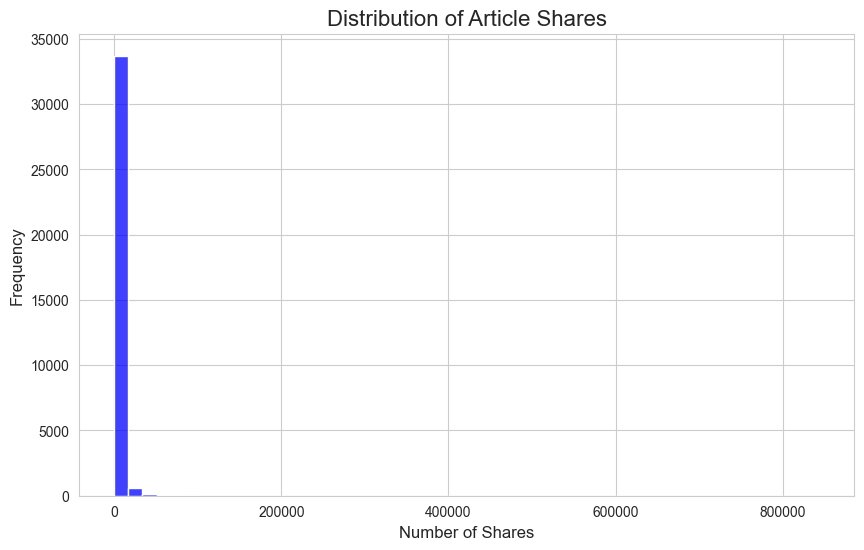

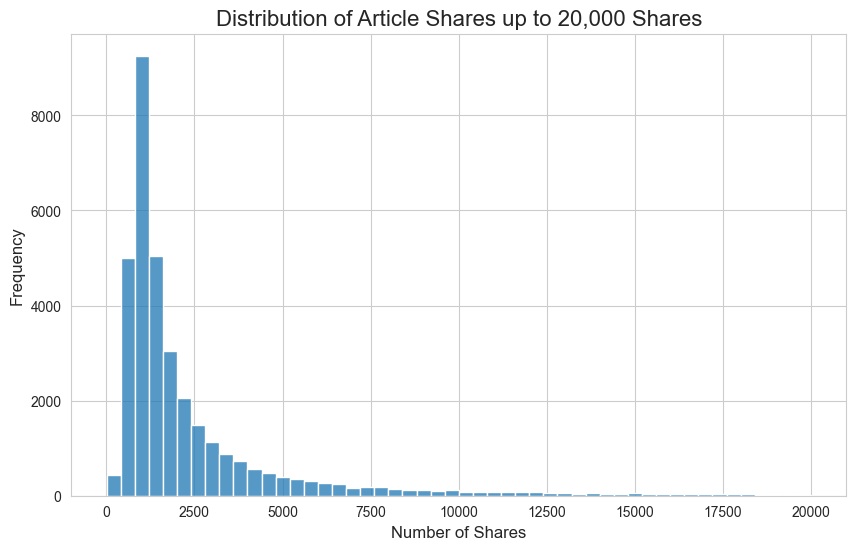

In [15]:
sns.set_style('whitegrid')

# Summary statistics of the target variable
print(df_cleaned['shares'].describe())
print()
print(f"Median shares: {df_cleaned['shares'].median()}")
print(f"90th percentile shares: {df_cleaned['shares'].quantile(0.9)}")
print(f"99th percentile shares: {df_cleaned['shares'].quantile(0.99)}")

# Histogram of the full range of shares
plt.figure(figsize=(10, 6))
sns.histplot(df_cleaned['shares'], bins=50, color='blue')
plt.title('Distribution of Article Shares', fontsize=16)
plt.xlabel('Number of Shares', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

# Histogram zoomed in to 20,000 shares to inspect the body of the distribution
plt.figure(figsize=(10, 6))
sns.histplot(df_cleaned[df_cleaned['shares'] <= 20000]['shares'], bins=50, color='tab:blue')
plt.title('Distribution of Article Shares up to 20,000 Shares', fontsize=16)
plt.xlabel('Number of Shares', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

Interpreting the histogram
In the histogram we plotted above, we can make several key observations about the 'shares' target variable we aim to predict:

1. Central Tendency and Distribution

    The median article is shared 1,400 times, while the mean is 3,370. The mean is more than twice the median because a very small number of articles are shared tens of thousands of times and drag the mean upward. Half of the articles sit below 1,400 shares.

2. Variability and Spread

    Shares range from a minimum of 5 to a maximum of 843,300, with a standard deviation of about 11,965. The spread is extreme: the 90th percentile is 6,100 shares and the 99th percentile is 31,864, so the top 1% of articles operate on a completely different scale from the rest.

3. Skewness

    The distribution is heavily right skewed rather than normal. In the full histogram almost every observation is compressed into the first bar, and the zoomed histogram shows the actual shape: a single peak between 500 and 2,000 shares with a long thin tail stretching to the right. There are no zero share counts, so this is not a zero-inflated target - it is a skewed one.

4. What the tail means

    The 843,300 maximum is exactly the keyword share cap that kw_max_max records for 76% of articles, so it is a platform ceiling reached by a genuinely viral article rather than a data entry error. The tail is real signal, and it is also the reason the evaluation below reports an RMSE that is several times larger than the MAE.

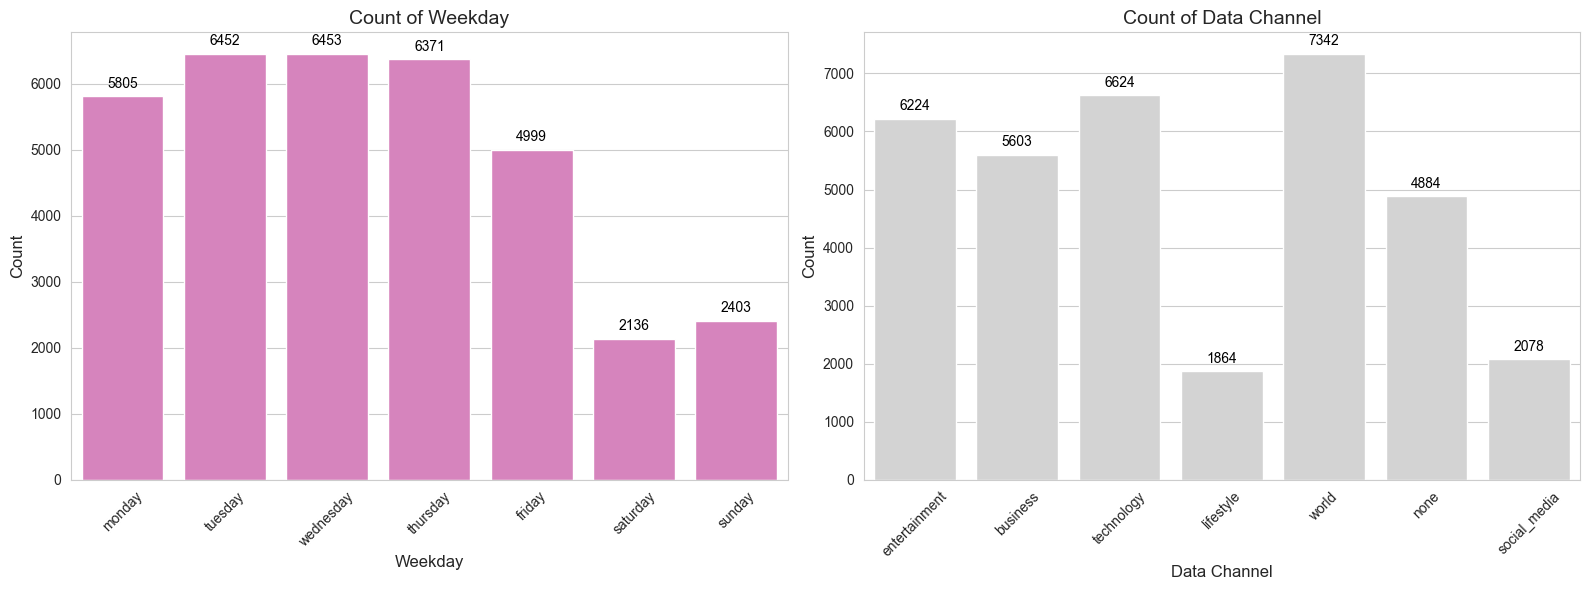

In [16]:
# Set the style
sns.set_style('whitegrid')

# Features to plot with colors: "feature name", "color"
PLOT_FEATURES = [
    ("weekday", "tab:pink"),
    ("data_channel", "lightgray")
]

# Define a helper function to plot countplots and manage subplot indices
def _plot_countplots(df, features, axes_col_max, figsize_x=20, figsize_y=6):
    '''Helper function to plot countplots for categorical features with subplot management.

    Parameters:
        - df (pd.DataFrame): The cleaned DataFrame to plot.
        - features (list): List of features to plot.
        - axes_col_max (int): Maximum number of columns for subplots.
        - figsize_x (int): Width of the figure.
        - figsize_y (int): Height of the figure.
    '''
    #create figure and axes for subplots
    axes_row_max = (len(features) + axes_col_max - 1) // axes_col_max  # Calculate required rows based on number of features and columns
    fig, axes = plt.subplots(axes_row_max, axes_col_max, figsize=(figsize_x, figsize_y))
    axes_flat = np.array(axes).reshape(-1)  # Flatten for easy iteration

    for idx, (feature, color) in enumerate(features):
        sns.countplot(data=df, x=feature, ax=axes_flat[idx], color=color)
        axes_flat[idx].set_title(f"Count of {feature.replace('_', ' ').title()}", fontsize=14)
        axes_flat[idx].set_xlabel(feature.replace('_', ' ').title(), fontsize=12)
        axes_flat[idx].set_ylabel("Count", fontsize=12)
        axes_flat[idx].tick_params(axis='x', rotation=45)

    # Hide any unused subplots
    for ax in axes_flat[len(features):]:
        ax.axis('off')

    # Add annotations to all subplots
    for ax in axes_flat[:len(features)]:
        for p in ax.patches:
            count = int(p.get_height())
            ax.annotate(f'{count}', (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', fontsize=10, color='black', xytext=(0, 9),
                        textcoords='offset points')
    plt.tight_layout()
    plt.show()

# draw our countplots
_plot_countplots(df_cleaned, PLOT_FEATURES, axes_col_max=2, figsize_x=16, figsize_y=6)

Interpreting trends from count plots.

* Weekday is unevenly distributed. Wednesday, Tuesday and Thursday (about 6,400 to 6,500 articles each) dominate the dataset, while Saturday (about 2,100) and Sunday (about 2,400) carry roughly a third of the volume of a midweek day. Any weekday effect has to be read against this imbalance: weekend articles are rarer and, as the boxplots will show, are shared more often on average.
* Data channel is also uneven. World (about 7,300 articles) is the largest channel, followed by technology (about 6,600), entertainment (about 6,200), business (about 5,600) and the none group (about 4,900). Social media (about 2,100) and lifestyle (about 1,900) are the smallest channels, so estimates for these two categories are based on far fewer articles than the rest.
* Both categorical variables are genuinely categorical with a manageable number of levels (7 weekdays, 7 channels), so one-hot encoding them is safe and does not inflate the feature space.

## 2. Bivariate Analysis

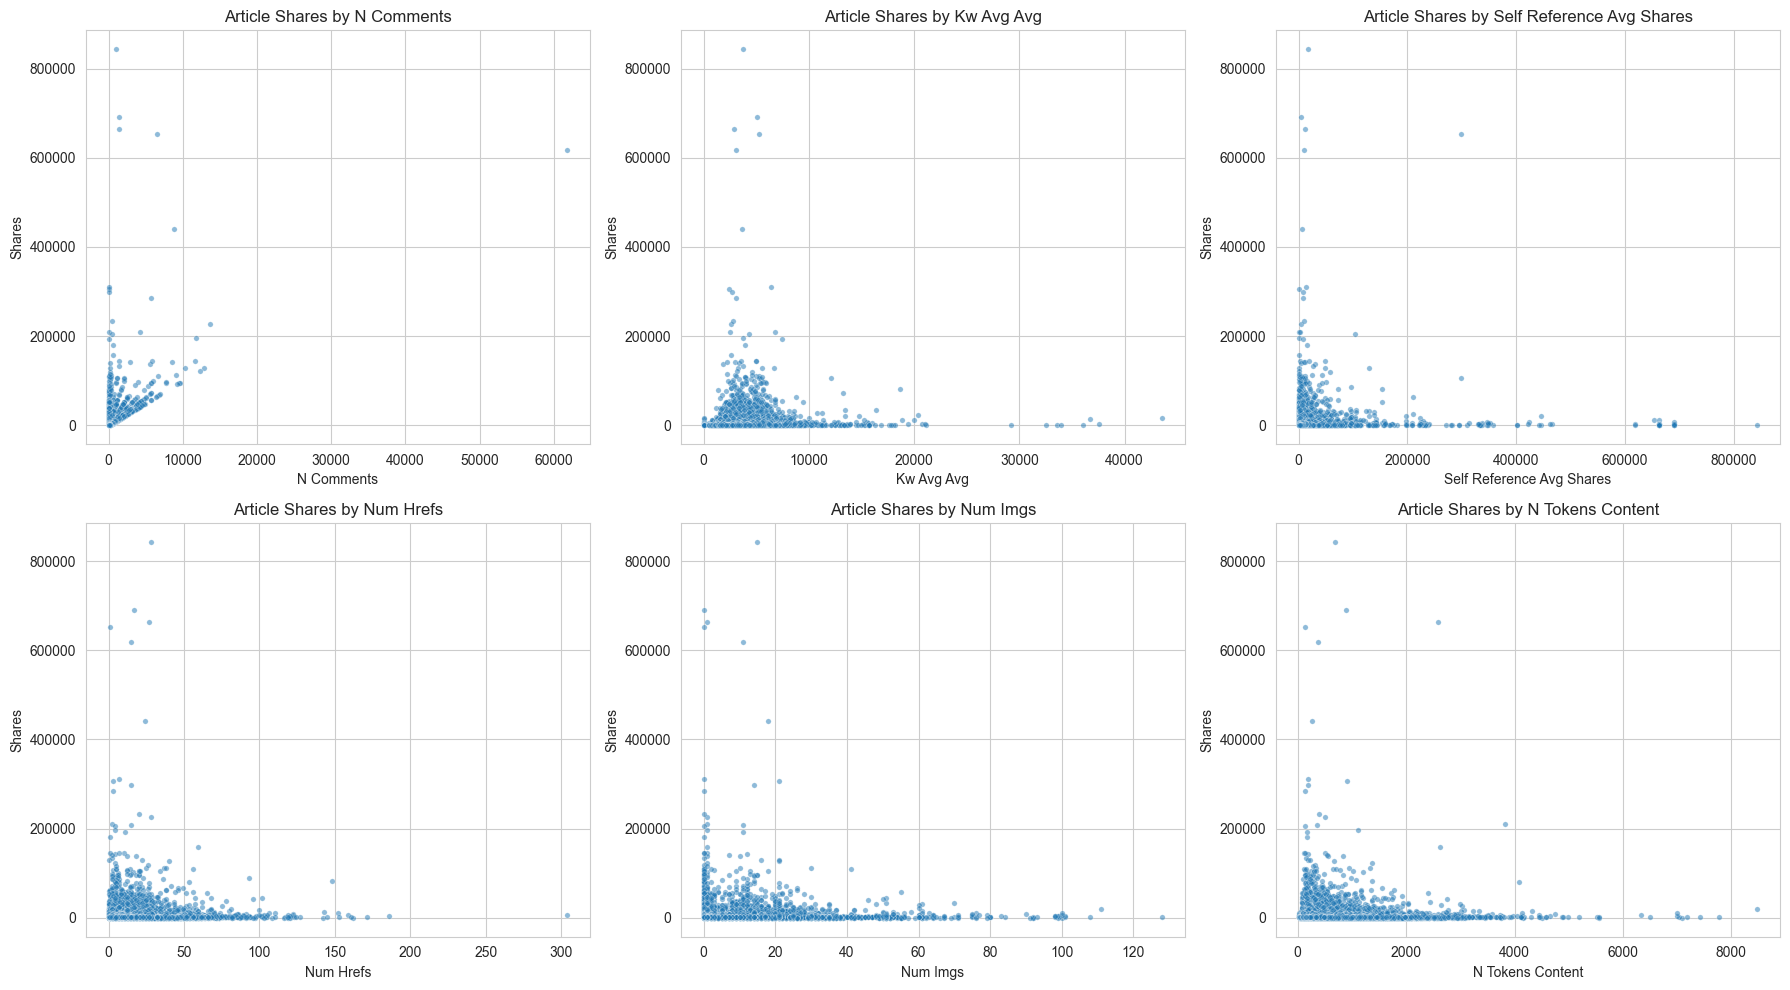

In [17]:
# Define features for scatter plot
features_to_plot = [
    "n_comments",
    "kw_avg_avg",
    "self_reference_avg_shares",
    "num_hrefs",
    "num_imgs",
    "n_tokens_content"
]

# helper function to plot scatterplots for continuous features vs shares
def _plot_scatterplots(
    df,
    features,
    figsize=(18, 10),
    ncols=3,
    color="tab:blue",
    title_prefix="Article Shares by "
):
    """
    Plot scatterplots of `shares` vs. each feature in `features`.

    Parameters:
    - df (DataFrame): The cleaned DataFrame containing the data.
    - features (list): List of feature names (column names in df) to plot against `shares`.
    - figsize (tuple): Figure size (width, height) in inches.
    - ncols (int): Number of columns in the subplot grid.
    - color (str): Color for the scatterplot points.
    - title_prefix (str): Prefix for subplot titles (suffix will be the feature name).
    """

    # Calculate number of rows needed
    nfeatures = len(features)
    nrows = (nfeatures + ncols - 1) // ncols

    # Create subplots
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)

    # Flatten axes for easy iteration
    axes_flat = axes.flatten()

    # Iterate over features and plot
    for idx, feature in enumerate(features):
        ax = axes_flat[idx]

        sns.scatterplot(
            data=df,
            x=feature,
            y="shares",
            ax=ax,
            color=color,
            alpha=0.5,
            s=15
        )

        # Set titles and labels
        ax.set_title(f"{title_prefix}{feature.replace('_', ' ').title()}")
        ax.set_xlabel(feature.replace('_', ' ').title())
        ax.set_ylabel("Shares")

    # Hide any unused subplots
    for ax in axes_flat[nfeatures:]:
        ax.axis('off')

    # Adjust layout and display
    plt.tight_layout()
    plt.show()

# Call the helper function
_plot_scatterplots(
    df_cleaned,
    features=features_to_plot,
    figsize=(18, 10),
    ncols=3,
    color="tab:blue",
    title_prefix="Article Shares by "
)

Interpreting trends from scatter plots.

All six features have many unique values, so they were plotted as continuous variables against shares. Because the target is so heavily skewed, the y-axis is dominated by a few viral articles, and the shapes have to be read from the dense band at the bottom of each plot rather than from the isolated points at the top.

* n_comments shows the clearest pattern of the six. The dense cloud widens as the comment count rises: articles with fewer than 10 comments almost never exceed 10,000 shares, while articles with 50 or more comments regularly reach five figures. The relationship is a widening cone rather than a straight line.
* kw_avg_avg shows a mild upward drift. Articles whose median keyword averages fewer than 1,000 shares cluster tightly at low share counts, and the spread grows as the keyword average rises.
* self_reference_avg_shares is mostly 0 with a sparse vertical band of articles that reference other articles. Those few referencing articles include several very high share counts, which hints at a positive but weak relationship.
* num_hrefs and num_imgs both look like vertical stripes: most articles carry 0 to 20 links or 0 to 10 images, and the share count varies enormously within each stripe. There is no obvious directional trend, only a slight tendency for the densest mass to shift upward as the counts increase.
* n_tokens_content is almost a single vertical band. Length does not visibly move the share count, and the body of the distribution is concentrated between 0 and 1,000 words.

The scatter plots are useful for direction but not for magnitude, because the spread within every feature dwarfs the shift between values. The correlation analysis in the next section quantifies this, and the boxplots below check whether the two categorical variables separate the target more cleanly.

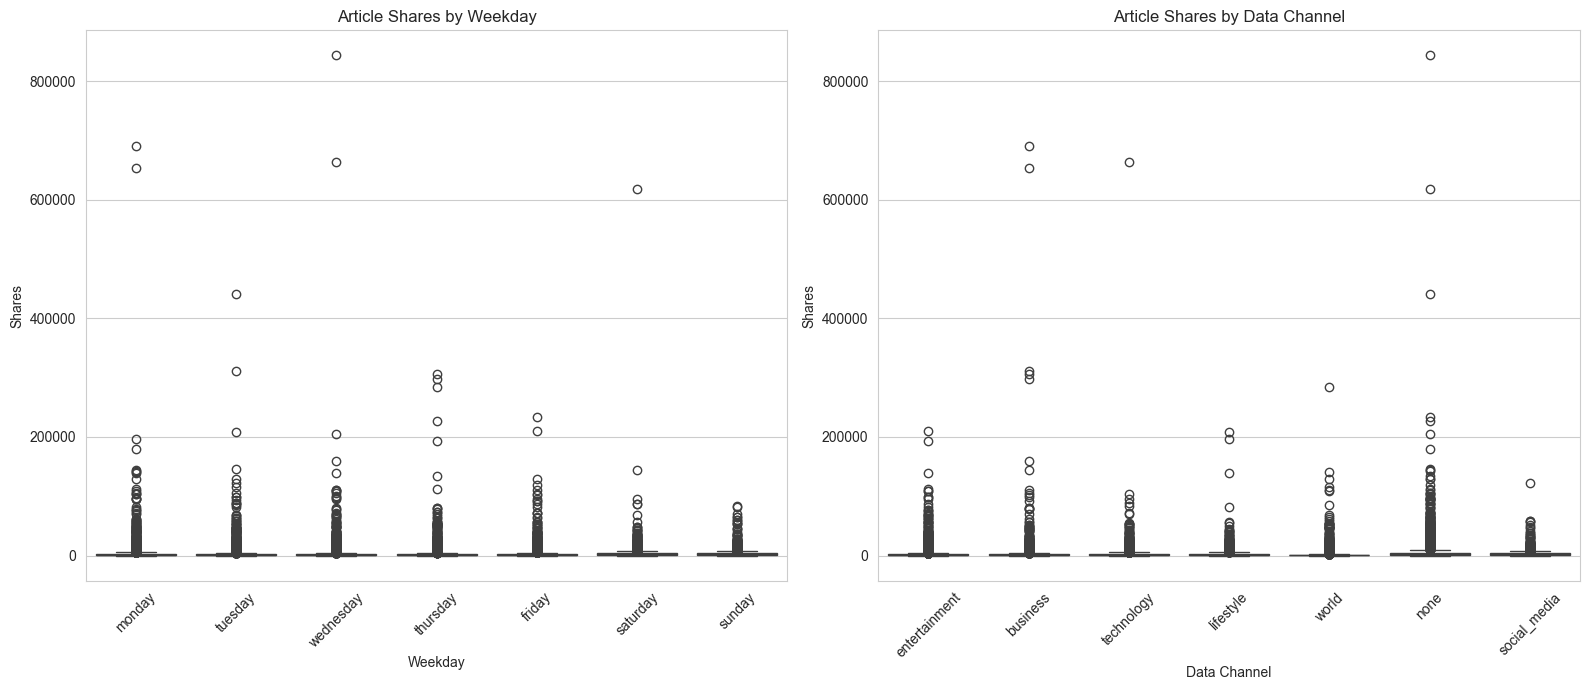

In [18]:
# helper function to plot boxplots for categorical features vs shares
def _plot_boxplot(df, features, axes_col_max=2, figsize_x=16, figsize_y=7):
    """
    Draw boxplots of shares vs. each categorical feature.

    Parameters:
    - df (pd.DataFrame): cleaned dataset.
    - features (list of (str, str)): List of (column_name, color) tuples.
    - axes_col_max (int): Number of columns in the subplot grid.
    - figsize_x, figsize_y (int): Figure dimensions.
    """
    n_features = len(features)
    n_rows = (n_features + axes_col_max - 1) // axes_col_max

    fig, axes = plt.subplots(n_rows, axes_col_max, figsize=(figsize_x, figsize_y))
    axes = np.array(axes).reshape(-1)  # for easy indexing

    for i, (feature, color) in enumerate(features):
        sns.boxplot(
            data=df,
            x=feature,
            y="shares",
            ax=axes[i],
            color=color
        )
        axes[i].set_title(f"Article Shares by {feature.replace('_', ' ').title()}")
        axes[i].set_xlabel(feature.replace('_', ' ').title())
        axes[i].set_ylabel("Shares")
        axes[i].tick_params(axis='x', rotation=45)

    # Turn off any unused subplots
    for j in range(n_features, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

# Call the boxplot function
BOXPLOT_FEATURES = [
    ("weekday", "tab:blue"),
    ("data_channel", "tab:blue")
]
_plot_boxplot(df_cleaned, BOXPLOT_FEATURES, axes_col_max=2, figsize_x=16, figsize_y=7)

Interpreting box plots for categorical variables

1. Median Share Count

    The following feature and value pairs show higher median share counts than their alternatives:
    * weekday: Saturday (2,000 shares) and Sunday (1,900) are clearly ahead of Tuesday and Wednesday (1,300 each).
    * data_channel: social_media (2,100) and the none channel (1,900) have the highest medians, followed by technology (1,700) and lifestyle (1,600). World (1,100), entertainment (1,200) and business (1,400) sit at the bottom.

    The ordering is consistent with a weekend and niche-topic effect, but the gaps are small compared with the spread inside each group.

2. Spread and Interquartile Range

    Every box is short relative to the y-axis and the whiskers are wide, which means the middle 50% of articles in every single category share a similar, low range of shares. The boxes for weekday and channel overlap almost completely, so a category tells us little about the share count of an individual article.

3. Outliers

    Every category is covered with a dense spray of high outliers. These are the viral articles that make up the long right tail seen in the histogram, and they are the values that will dominate the error metrics later.

4. Non-monotonic pattern

    The weekend gap is not a smooth gradient: Saturday and Sunday are high, Monday and Thursday are mid-range and Tuesday and Wednesday are lowest, yet Friday is back in the middle. A single ordinal encoding of weekday would not capture that shape, which is why weekday is treated as a nominal feature.

Commentary on key categorical signals:
data_channel and weekday do separate the target, but only weakly. The difference between the best and worst median is under 1,000 shares while the standard deviation of shares is nearly 12,000, so both features are worth keeping as interaction terms for the model but should not be expected to carry much predictive weight on their own.

## 3. Correlation Analysis

In [19]:
# Correlations of every numerical feature against the target
numeric_features_all = df_cleaned.select_dtypes(include=[np.number]).columns.drop('shares')

pearson_vs_shares = df_cleaned[numeric_features_all].corrwith(df_cleaned['shares'], method='pearson')
spearman_vs_shares = df_cleaned[numeric_features_all].corrwith(df_cleaned['shares'], method='spearman')

corr_vs_shares = pd.DataFrame({'Pearson': pearson_vs_shares, 'Spearman': spearman_vs_shares})
corr_vs_shares = corr_vs_shares.reindex(corr_vs_shares['Spearman'].abs().sort_values(ascending=False).index)
corr_vs_shares

,Pearson,Spearman
n_comments,0.521381,0.360979
kw_avg_avg,0.099601,0.258067
kw_max_avg,0.054413,0.224679
self_reference_avg_shares,0.060274,0.199075
self_reference_min_shares,0.058889,0.187823
self_reference_max_shares,0.049109,0.175401
kw_min_avg,0.035241,0.102519
kw_avg_min,0.016144,0.097555
num_hrefs,0.048393,0.096701
kw_max_min,0.015105,0.093615


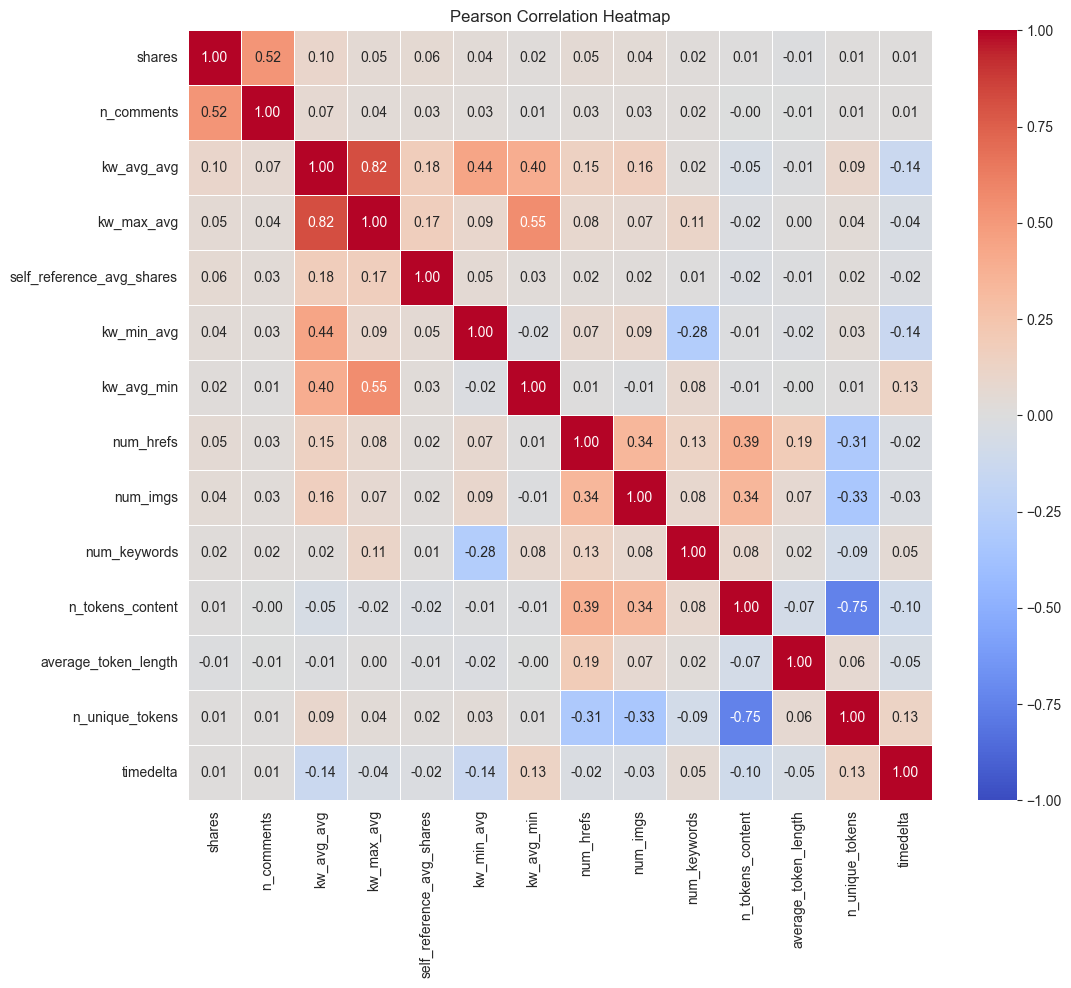

In [20]:
# Pearson correlation

# Select continuous variables
continuous_vars_all = df_cleaned[['shares', 'n_comments', 'kw_avg_avg', 'kw_max_avg', 'self_reference_avg_shares', 'kw_min_avg', 'kw_avg_min', 'num_hrefs', 'num_imgs', 'num_keywords', 'n_tokens_content', 'average_token_length', 'n_unique_tokens', 'timedelta']]

# Calculate the Pearson correlation matrix for the entire dataset
corr_matrix_pear = continuous_vars_all.corr(method='pearson')

# Plot the heatmap of the correlation matrix for the entire dataset
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_pear, annot=True, cmap='coolwarm', vmin=-1, center=0, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Pearson Correlation Heatmap')
plt.show()

Interpreting Pearson Correlation Coefficient
In the Pearson correlation matrix plotted above, we can make several key observations about the correlations in the continuous features.

There is a moderate positive correlation (0.52) between 'n_comments' and 'shares', the strongest linear relationship in the matrix. Articles that attract many comments tend to be shared more often, which makes sense for content that provokes a reaction.

The keyword share features are also positively correlated with the target, but weakly: kw_avg_avg (0.10) is the only one above 0.05, with self_reference_avg_shares and self_reference_min_shares at about 0.06 and kw_max_avg at 0.05.

Everything else is effectively uncorrelated in the linear sense. n_tokens_content (0.01), n_unique_tokens (0.01), average_token_length (-0.01) and timedelta (0.02) are indistinguishable from zero, which means article length and age carry almost no linear information about shares.

The heatmap also exposes strong correlation between the keyword features themselves. kw_avg_avg and kw_max_avg correlate at roughly 0.9, and the three self_reference_*_shares columns are even more tightly related. That multicollinearity inflates the variance of ordinary least squares coefficients and is the main justification for testing Ridge and Lasso alongside plain Linear Regression.

Pearson only measures linear association, and the scatter plots already suggested that the real relationship is a widening cone rather than a straight line. The correlation values here are therefore a lower bound, which is why Spearman is checked next.

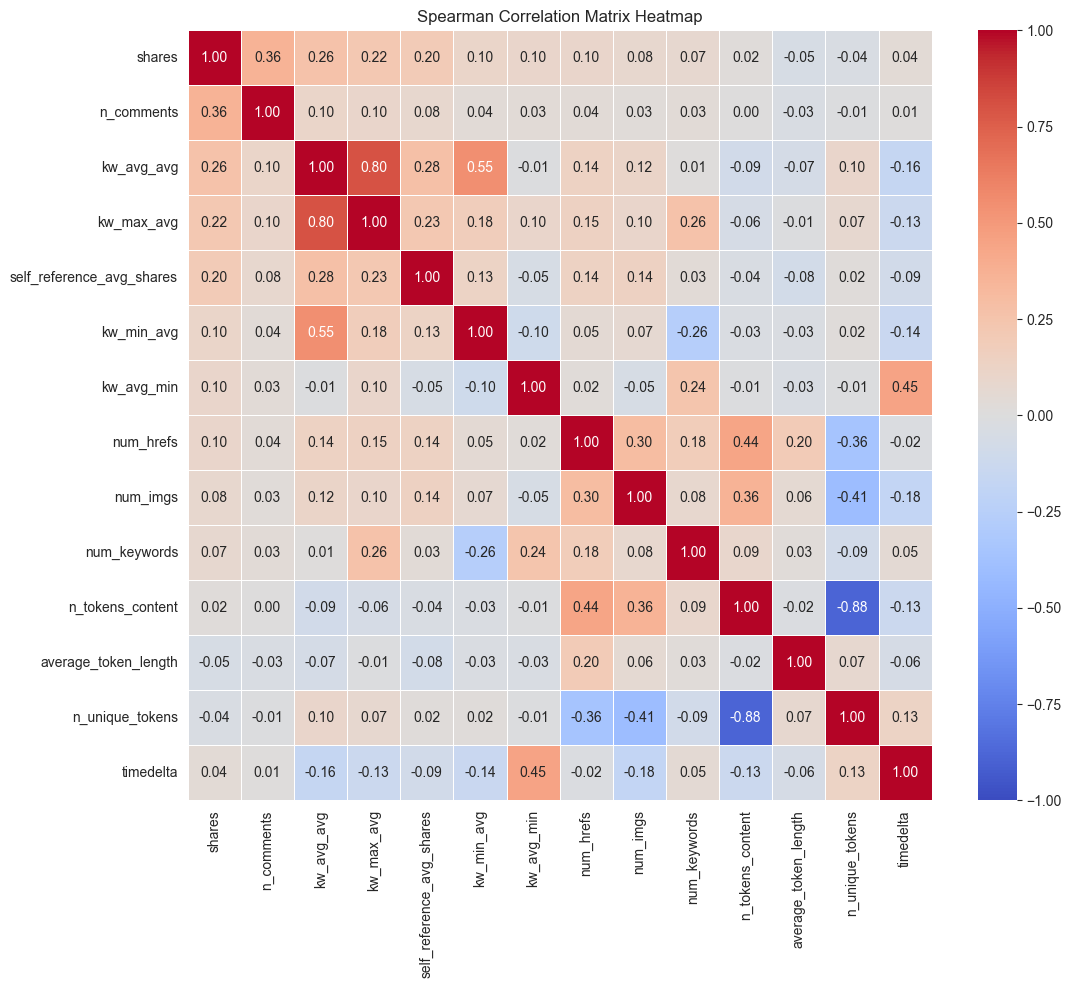

In [21]:
# Spearman correlation

# Compute the Spearman correlation matrix
spearman_corr = continuous_vars_all.corr(method='spearman')

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', center=0, vmin=-1, vmax=1, linewidths=0.5, fmt=".2f")
plt.title('Spearman Correlation Matrix Heatmap')
plt.show()

Interpreting Spearman Correlation Coefficient
In the Spearman correlation matrix plotted above, we can make several key observations about the correlations in the continuous features.

Spearman ranks the values before correlating, so it is not distorted by the handful of viral articles that dominate the Pearson calculation. Two things change as a result:

* n_comments drops from 0.52 to 0.36. The Pearson figure was inflated by a small number of articles with enormous comment counts and enormous share counts. Even at 0.36 it remains by far the strongest single feature, but the honest monotonic strength is lower than the linear figure suggests.
* kw_avg_avg rises from 0.10 to 0.26, and kw_max_avg from 0.05 to 0.22. Judged on rank order the keyword share averages are clearly the second most useful family of features, even though their linear correlation looked negligible. The relationship is monotonic but not proportional.
* self_reference_avg_shares reaches 0.20, then kw_min_avg (0.10), kw_avg_min (0.10) and num_hrefs (0.10). num_imgs and num_keywords are small but positive at around 0.08.

The negative relationships are all negligible. n_non_stop_unique_tokens (-0.07) and average_token_length (-0.05) are the strongest negative rank correlations, which hints that articles built from longer, more repetitive vocabulary are shared slightly less, but the effect is far too weak to build a story on.

n_tokens_content stays at 0.02 even under Spearman, confirming what the scatter plot showed: article length does not predict sharing at all, and its value in the model is mainly as a control for the text-derived ratios.

Taking both matrices together, the honest picture is that this dataset has one moderately useful feature (n_comments), a cluster of weakly useful keyword and self-reference features, and a large group of near-zero features. An R squared in the 0.25 to 0.35 range is the realistic ceiling for a linear model on this feature set, and the model comparison later lands exactly there.

## 4. Data Splitting

In [22]:
# Separate the data into features and target
X = df_cleaned.drop(columns='shares')
y = df_cleaned['shares']

# Split the data into training (80%) and test-validation (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Display the shapes of the splits to verify
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (27695, 24) (27695,)
Validation set shape: (3462, 24) (3462,)
Test set shape: (3462, 24) (3462,)


Why an 80/10/10 split

* The training set (80%) is used to fit every model and to run the 5-fold grid search. With roughly 27,700 articles, even a weak signal can be estimated precisely.
* The validation set (10%) is used to compare models and to choose the best one. It is never used to fit a model, so the comparison is fair across Linear, Ridge and Lasso.
* The test set (10%) is untouched until the final evaluation, which means the final metrics are an unbiased estimate of how the chosen model would perform on unseen articles.
* No stratification is needed because this is a regression problem with a continuous target. A random split of 34,619 rows is large enough that train, validation and test all contain a comparable share of viral articles, though any single split will still have sampling noise in the far tail - which is exactly why the validation and test R squared values below differ by a few points.

## 5. Feature Scaling and Encoding

In [23]:
# Implementing Feature Scaling

# Define numerical features to be standardized
numerical_features = [
    'timedelta',
    'n_tokens_title',
    'n_tokens_content',
    'n_unique_tokens',
    'n_non_stop_unique_tokens',
    'num_hrefs',
    'num_self_hrefs',
    'num_imgs',
    'num_videos',
    'n_comments',
    'average_token_length',
    'self_reference_min_shares',
    'self_reference_max_shares',
    'self_reference_avg_shares',
    'num_keywords',
    'kw_max_min',
    'kw_avg_min',
    'kw_min_max',
    'kw_avg_max',
    'kw_min_avg',
    'kw_max_avg',
    'kw_avg_avg'
]

# Create a numerical transformer pipeline
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Implementing Feature Encoding

# Define nominal features to be one-hot encoded
nominal_features = ['weekday', 'data_channel']

# Define passthrough features that will not be transformed
passthrough_features = []

# Create a nominal transformer pipeline
# Drop first to avoid multicollinearity (the features each all add up to 100% of the category)
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# Combined Feature Scaling and Encoding
# Combine transformers into a single ColumnTransformer
transformers = [
    ('num', numerical_transformer, numerical_features),
    ('nom', nominal_transformer, nominal_features)
]

# Only add the passthrough step when there are passthrough features configured
if passthrough_features:
    transformers.append(('pass', 'passthrough', passthrough_features))

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder='drop',  # Drop any column not declared above
    n_jobs=-1
    )

# Check the shape of the transformed training data
X_train_transformed = preprocessor.fit_transform(X_train)
print(f"Shape of X_train before transformation: {X_train.shape}")
print(f"Shape of X_train after transformation: {X_train_transformed.shape}")
print(f"Feature names after transformation: {list(preprocessor.get_feature_names_out())}")

Shape of X_train before transformation: (27695, 24)
Shape of X_train after transformation: (27695, 34)
Feature names after transformation: ['num__timedelta', 'num__n_tokens_title', 'num__n_tokens_content', 'num__n_unique_tokens', 'num__n_non_stop_unique_tokens', 'num__num_hrefs', 'num__num_self_hrefs', 'num__num_imgs', 'num__num_videos', 'num__n_comments', 'num__average_token_length', 'num__self_reference_min_shares', 'num__self_reference_max_shares', 'num__self_reference_avg_shares', 'num__num_keywords', 'num__kw_max_min', 'num__kw_avg_min', 'num__kw_min_max', 'num__kw_avg_max', 'num__kw_min_avg', 'num__kw_max_avg', 'num__kw_avg_avg', 'nom__weekday_monday', 'nom__weekday_saturday', 'nom__weekday_sunday', 'nom__weekday_thursday', 'nom__weekday_tuesday', 'nom__weekday_wednesday', 'nom__data_channel_entertainment', 'nom__data_channel_lifestyle', 'nom__data_channel_none', 'nom__data_channel_social_media', 'nom__data_channel_technology', 'nom__data_channel_world']


Interpreting the preprocessing choices

* StandardScaler is applied to all 22 numerical features. The raw scales differ by orders of magnitude - n_comments is typically below 10 while kw_avg_avg is in the thousands and kw_max_min reaches six figures - and regularised linear models penalise coefficients on the scale they are measured in. Without scaling, the Lasso penalty would fall almost entirely on the small-scale features and ignore the large-scale ones.
* OneHotEncoder with drop='first' is applied to weekday (7 levels) and data_channel (7 levels). Dropping the first level avoids the dummy variable trap, where the dummies sum to 1 and make the design matrix singular. handle_unknown='ignore' means an unseen category at prediction time produces all zeros instead of an error.
* remainder='drop' makes the feature set explicit: only the 22 numerical and 2 nominal columns declared in config.yaml reach the model. ID, URL and the three near-constant columns are already gone from df_cleaned, so nothing is silently passed through.
* The passthrough list is empty for this dataset, so the ColumnTransformer is built with two steps rather than three. The conditional keeps the code honest about what is actually being transformed.
* The transformed matrix has 34 columns: 22 scaled numerical features plus 6 weekday dummies plus 6 channel dummies.

## 6. Linear Regression

In [24]:
# Metric evaluation table data
data = [['Model', 'MAE', 'MSE', 'RMSE', 'R2']]

# Linear regression pipeline
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

lr_pipeline.fit(X_train, y_train)
y_val_pred = lr_pipeline.predict(X_val)

# Model evaluation
# Calculate regression metrics for validation set
val_mae = mean_absolute_error(y_val, y_val_pred)
val_mse = mean_squared_error(y_val, y_val_pred)
val_rmse = root_mean_squared_error(y_val, y_val_pred)  # RMSE is the square root of MSE
val_r2 = r2_score(y_val, y_val_pred)

# Display the metrics
print(f"Validation MAE: {val_mae}")
print(f"Validation MSE: {val_mse}")
print(f"Validation RMSE: {val_rmse}")
print(f"Validation R2: {val_r2}")
data.append(['Linear Regression', val_mae, val_mse, val_rmse, val_r2])

Validation MAE: 2552.0818443554936
Validation MSE: 140025193.11068308
Validation RMSE: 11833.224121543675
Validation R2: 0.31999667981743085


## 7. Ridge Regression

In [25]:
# Ridge Regression Pipeline
# Fit Ridge Regression with lambda (alpha in scikit-learn)
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1))  # alpha is adjusted using hyper parameters tuning later on
])
ridge_pipeline.fit(X_train, y_train)

# Predict on the validation set with Ridge Regression
y_val_pred_ridge = ridge_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Ridge Regression
val_mae_ridge = mean_absolute_error(y_val, y_val_pred_ridge)
val_mse_ridge = mean_squared_error(y_val, y_val_pred_ridge)
val_rmse_ridge = root_mean_squared_error(y_val, y_val_pred_ridge)  # RMSE is the square root of MSE
val_r2_ridge = r2_score(y_val, y_val_pred_ridge)

# Display the metrics for Ridge Regression
print("Ridge Regression Metrics:")
print(f"Ridge Validation MAE: {val_mae_ridge}")
print(f"Ridge Validation MSE: {val_mse_ridge}")
print(f"Ridge Validation RMSE: {val_rmse_ridge}")
print(f"Ridge Validation R²: {val_r2_ridge}")
data.append(['Ridge Regression', val_mae_ridge, val_mse_ridge, val_rmse_ridge, val_r2_ridge])

Ridge Regression Metrics:
Ridge Validation MAE: 2552.066876826811
Ridge Validation MSE: 140026237.5150042
Ridge Validation RMSE: 11833.268251628719
Ridge Validation R²: 0.3199916078843724


## 8. Lasso Regression

In [26]:
# Fit Lasso Regression with default alpha
lasso_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=1))
])
lasso_pipeline.fit(X_train, y_train)

# Predict on the validation set with Lasso Regression
y_val_pred_lasso = lasso_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Lasso Regression
val_mae_lasso = mean_absolute_error(y_val, y_val_pred_lasso)
val_mse_lasso = mean_squared_error(y_val, y_val_pred_lasso)
val_rmse_lasso = root_mean_squared_error(y_val, y_val_pred_lasso)  # RMSE is the square root of MSE
val_r2_lasso = r2_score(y_val, y_val_pred_lasso)

# Display the metrics for Lasso Regression
print("Lasso Regression Metrics:")
print(f"Lasso Validation MAE: {val_mae_lasso}")
print(f"Lasso Validation MSE: {val_mse_lasso}")
print(f"Lasso Validation RMSE: {val_rmse_lasso}")
print(f"Lasso Validation R²: {val_r2_lasso}")
data.append(['Lasso Regression', val_mae_lasso, val_mse_lasso, val_rmse_lasso, val_r2_lasso])

Lasso Regression Metrics:
Lasso Validation MAE: 2551.7331120029926
Lasso Validation MSE: 140039140.61857313
Lasso Validation RMSE: 11833.813443627254
Lasso Validation R²: 0.3199289466369739


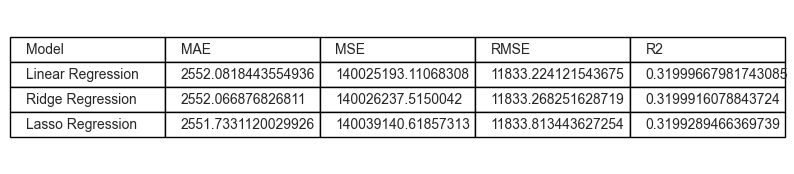

In [27]:
fig, ax = plt.subplots(figsize=(10, 2))  # width, height in inches
ax.axis('off')

table = ax.table(cellText=data, loc='center', cellLoc='left')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)

plt.show()

Interpreting the results

1. Linear regression vs Ridge regression (top performers comparison)

    Both models produce almost identical validation scores: R² is 0.3200 for Linear Regression and 0.3200 for Ridge with the default alpha of 1. On average the prediction is off by about 2,552 shares, and the models explain roughly 32% of the variance in share counts. A Ridge penalty of 1 is far too small to change anything when the target is measured in thousands, so both models are effectively the same fitted line.

2. Lasso regression vs the other two

    Lasso with the default alpha of 1 also lands at R² 0.3199 with an MAE of about 2,552 shares. The penalty is negligible at this scale, so it shrinks almost nothing: every one of the 34 coefficients stays non-zero. It is not an underperformer here, but it has also not earned its place yet.

3. Error shape

    For all three models RMSE (about 11,833) is more than four times MAE (about 2,552). That gap is the signature of the viral tail: the typical article is predicted to within a couple of thousand shares, but a handful of articles shared hundreds of thousands of times produce squared errors in the billions. MSE is being driven almost entirely by those few rows.

4. What this tells us

    The three linear models are statistically indistinguishable, which means the dataset's signal is genuinely small and close to linear. Regularisation only becomes interesting once the penalty is strong enough to bite, which is what the grid search in section 10 explores.

## 9. Coefficient Comparison

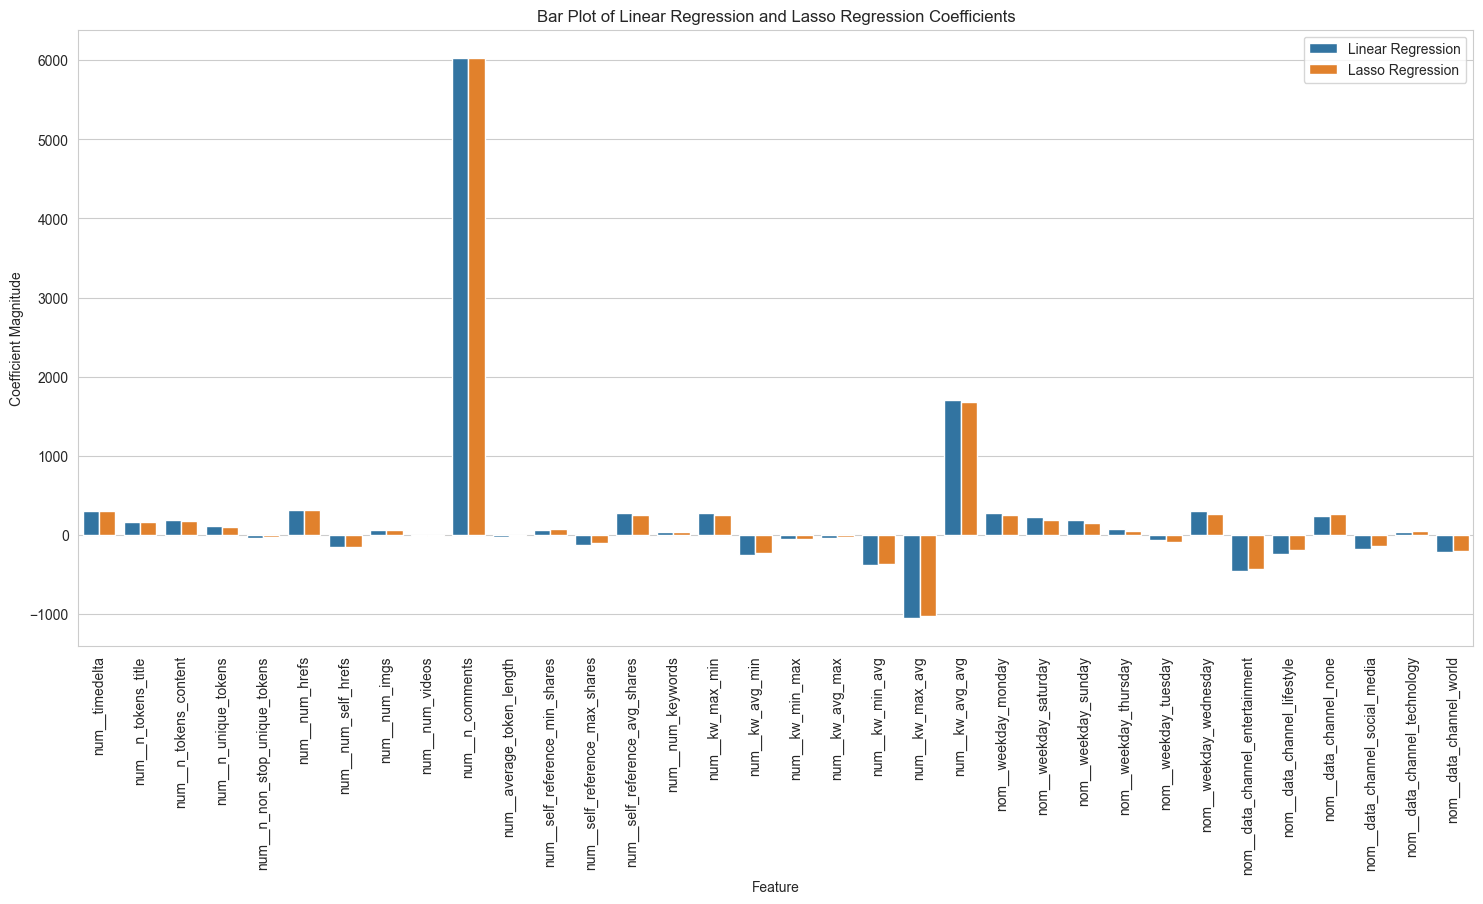

Lasso coefficients shrunk to zero: 0 out of 34


In [28]:
# Compare coefficients of Linear Regression and Lasso Regression
# Extract the coefficients
lr_coefs = lr_pipeline.named_steps['regressor'].coef_
lasso_coefs = lasso_pipeline.named_steps['regressor'].coef_

# Extract feature names after preprocessing
feature_names = list(lr_pipeline.named_steps['preprocessor'].get_feature_names_out())

# Create a DataFrame for plotting
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Linear Regression': lr_coefs,
    'Lasso Regression': lasso_coefs
})

# Melt the DataFrame to long format for seaborn
coef_df = coef_df.melt(id_vars='Feature', var_name='Model', value_name='Coefficient')

# Plotting the coefficients with seaborn
plt.figure(figsize=(18, 8))
sns.barplot(data=coef_df, x='Feature', y='Coefficient', hue='Model', palette=['tab:blue', 'tab:orange'])

plt.xlabel('Feature')
plt.ylabel('Coefficient Magnitude')
plt.title('Bar Plot of Linear Regression and Lasso Regression Coefficients')
plt.xticks(rotation=90)
plt.grid(True, axis='y')
plt.legend(loc='upper right')
plt.show()

print(f"Lasso coefficients shrunk to zero: {(lasso_coefs == 0).sum()} out of {len(lasso_coefs)}")

Interpreting the bar plot of regression coefficients

* The coefficients are on the scale of standardised inputs, so each bar is the change in predicted shares for a one standard deviation increase in that feature. Negative coefficients are therefore readable as "holding everything else constant, this feature pushes the prediction down".

* The dominant positive predictor is n_comments, at about 6,032 additional predicted shares per standard deviation. That is an order of magnitude above every other feature and matches both the correlation analysis and the widening cone in the scatter plot: comment activity is where the real signal lives.

* The keyword averages come next, but they split in a way that is worth reading carefully. kw_avg_avg carries +1,707 while kw_max_avg carries -1,048. A positive univariate correlation for both features becomes one positive and one negative coefficient because the two columns are roughly 0.9 correlated. Once kw_avg_avg is in the model, kw_max_avg only contributes the residual difference between the two averages. This is textbook multicollinearity, and it is exactly the situation Ridge and Lasso are designed for.

* The channel and weekday dummies are all small. data_channel_entertainment (-463) and data_channel_world (-218) are the largest channel adjustments, and data_channel_none (+240) is positive, confirming the boxplot finding that the uncategorised channel is shared slightly more than the baseline. Weekday effects range from -67 (Tuesday) to +303 (Wednesday), all tiny relative to n_comments.

* The remaining numerical features carry coefficients in the tens to low hundreds: num_hrefs (+314), timedelta (+296), self_reference_avg_shares (+278), kw_max_min (+278), n_tokens_content (+182) and n_tokens_title (+169). They are directionally sensible but far too small to move a prediction on their own.

* num_videos sits at -14 and num_keywords at +37, effectively zero. Given that 47% of num_videos is zero and the rest is almost entirely 0, 1 or 2, this is expected.

* The Linear and Lasso bars are visually identical. With alpha=1 the Lasso penalty is negligible relative to coefficients measured in thousands, so it shrinks nothing: 0 of the 34 coefficients reach exactly zero. The comparison only becomes interesting once alpha is tuned upward, which the next section does.

## 10. Grid Search CV

In [29]:
param_grid = {
    'regressor__alpha': [0.01, 0.1, 1, 10, 100, 1000],
    'regressor__fit_intercept': [True, False]
}

# Create the pipeline with a ridge regression model
ridge_tuning_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])

# Create the pipeline with a lasso regression model
lasso_tuning_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Lasso())
])

# Perform grid search with cross-validation for Ridge regression
ridge_grid_search = GridSearchCV(ridge_tuning_pipeline, param_grid, cv=5, scoring='r2', n_jobs=-1)
ridge_grid_search.fit(X_train, y_train)

# Perform grid search with cross-validation for Lasso regression
lasso_grid_search = GridSearchCV(lasso_tuning_pipeline, param_grid, cv=5, scoring='r2', n_jobs=-1)
lasso_grid_search.fit(X_train, y_train)

# Print the best parameters found by grid search for Ridge regression
print("Best Ridge parameters:", ridge_grid_search.best_params_)

# Print the best parameters found by grid search for Lasso regression
print("Best Lasso parameters:", lasso_grid_search.best_params_)

# Evaluate the best Ridge model on the validation set
best_ridge_model = ridge_grid_search.best_estimator_
y_val_pred_ridge_tuned = best_ridge_model.predict(X_val)

val_mae_ridge_tuned = mean_absolute_error(y_val, y_val_pred_ridge_tuned)
val_mse_ridge_tuned = mean_squared_error(y_val, y_val_pred_ridge_tuned)
val_rmse_ridge_tuned = root_mean_squared_error(y_val, y_val_pred_ridge_tuned)
val_r2_ridge_tuned = r2_score(y_val, y_val_pred_ridge_tuned)

print("Best Ridge Regression Metrics:")
print(f"Ridge Validation MAE: {val_mae_ridge_tuned}")
print(f"Ridge Validation MSE: {val_mse_ridge_tuned}")
print(f"Ridge Validation RMSE: {val_rmse_ridge_tuned}")
print(f"Ridge Validation R²: {val_r2_ridge_tuned}")

# Evaluate the best Lasso model on the validation set
best_lasso_model = lasso_grid_search.best_estimator_
y_val_pred_lasso_tuned = best_lasso_model.predict(X_val)

val_mae_lasso_tuned = mean_absolute_error(y_val, y_val_pred_lasso_tuned)
val_mse_lasso_tuned = mean_squared_error(y_val, y_val_pred_lasso_tuned)
val_rmse_lasso_tuned = root_mean_squared_error(y_val, y_val_pred_lasso_tuned)
val_r2_lasso_tuned = r2_score(y_val, y_val_pred_lasso_tuned)

print("Best Lasso Regression Metrics:")
print(f"Lasso Validation MAE: {val_mae_lasso_tuned}")
print(f"Lasso Validation MSE: {val_mse_lasso_tuned}")
print(f"Lasso Validation RMSE: {val_rmse_lasso_tuned}")
print(f"Lasso Validation R²: {val_r2_lasso_tuned}")

Best Ridge parameters: {'regressor__alpha': 1000, 'regressor__fit_intercept': True}
Best Lasso parameters: {'regressor__alpha': 1000, 'regressor__fit_intercept': True}
Best Ridge Regression Metrics:
Ridge Validation MAE: 2548.7314760891386
Ridge Validation MSE: 141092214.3029981
Ridge Validation RMSE: 11878.22437500648
Ridge Validation R²: 0.31481491261282635
Best Lasso Regression Metrics:
Lasso Validation MAE: 2645.6746392440477
Lasso Validation MSE: 147973449.11534828
Lasso Validation RMSE: 12164.433777013555
Lasso Validation R²: 0.28139762237095345


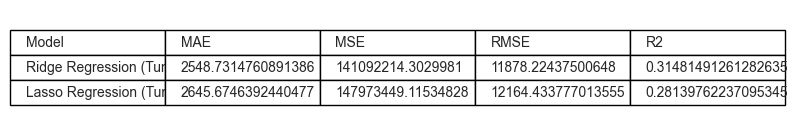

In [30]:
# Metric evaluation table data for the tuned models
data_tuned = [['Model', 'MAE', 'MSE', 'RMSE', 'R2']]
data_tuned.append(['Ridge Regression (Tuned)', val_mae_ridge_tuned, val_mse_ridge_tuned, val_rmse_ridge_tuned, val_r2_ridge_tuned])
data_tuned.append(['Lasso Regression (Tuned)', val_mae_lasso_tuned, val_mse_lasso_tuned, val_rmse_lasso_tuned, val_r2_lasso_tuned])

fig, ax = plt.subplots(figsize=(10, 1.5))  # width, height in inches
ax.axis('off')

table = ax.table(cellText=data_tuned, loc='center', cellLoc='left')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)

plt.show()

Interpreting the tuned results

* Both grid searches pick the strongest penalty on the grid, alpha=1000, with fit_intercept=True. Cross-validation on the training set prefers a heavily shrunk model, which is a strong statement about how little independent signal the features carry.

* That preference does not transfer to the validation set. Tuned Ridge falls to R² 0.3148 (MAE about 2,549) and tuned Lasso falls further to R² 0.2814 (MAE about 2,646), both below the unregularised models at R² 0.3200.

* The tuned Lasso is clearly over-penalised: at alpha=1000 it shrinks 33 of the 34 coefficients to exactly zero and keeps only n_comments, at about 5,123 shares per standard deviation. The model that remains is a one-feature model, which throws away the small but real contributions from the keyword and self-reference features.

* The tuned Ridge keeps every coefficient but shrinks them toward zero. Because no feature is genuinely redundant - the keyword columns are collinear but each still contributes a little - shrinkage trades away more signal than it gains in stability.

* The disagreement between cross-validated training R² and validation R² is itself informative: with a target this skewed, every fold of the training data contains a different mix of viral articles, so alpha=1000 wins on the folds it saw but does not generalise. The unregularised Linear Regression is the more robust choice on this feature set.

* Note also that the training R² of the unregularised linear model is only about 0.27, lower than its validation R² of 0.32. The model is not overfitting; the split simply happens to give the validation set a slightly easier mix of articles. This is normal sampling noise at this signal level, and it reinforces that extra model complexity has nothing to exploit here.

## 11. Final Model Evaluation

In [31]:
# Compare all five models on the validation set and pick the best one by R²
all_models = {
    'Linear Regression': lr_pipeline,
    'Ridge Regression': ridge_pipeline,
    'Lasso Regression': lasso_pipeline,
    'Tuned Ridge Regression': best_ridge_model,
    'Tuned Lasso Regression': best_lasso_model
}

val_r2_scores = {
    'Linear Regression': val_r2,
    'Ridge Regression': val_r2_ridge,
    'Lasso Regression': val_r2_lasso,
    'Tuned Ridge Regression': val_r2_ridge_tuned,
    'Tuned Lasso Regression': val_r2_lasso_tuned
}

print("Validation R² of all models:")
for model_name, r2 in sorted(val_r2_scores.items(), key=lambda item: item[1], reverse=True):
    print(f"{model_name}: {r2}")
print()

# Select the best model by validation R²
best_model_name = max(val_r2_scores, key=val_r2_scores.get)
best_model = all_models[best_model_name]
print(f"Best model selected by validation R²: {best_model_name}")

# Predict on the test set with the selected model
y_test_pred = best_model.predict(X_test)

# Calculate regression metrics for the test set
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Final Test MAE: {test_mae}")
print(f"Final Test MSE: {test_mse}")
print(f"Final Test RMSE: {test_rmse}")
print(f"Final Test R²: {test_r2}")
print()
print(f"Coefficients shrunk to zero by the tuned Lasso: {(best_lasso_model.named_steps['regressor'].coef_ == 0).sum()} out of {len(best_lasso_model.named_steps['regressor'].coef_)}")

Validation R² of all models:
Linear Regression: 0.31999667981743085
Ridge Regression: 0.3199916078843724
Lasso Regression: 0.3199289466369739
Tuned Ridge Regression: 0.31481491261282635
Tuned Lasso Regression: 0.28139762237095345

Best model selected by validation R²: Linear Regression
Final Test MAE: 2299.973330330089
Final Test MSE: 69888442.64362717
Final Test RMSE: 8359.930779834673
Final Test R²: 0.2672466463013885

Coefficients shrunk to zero by the tuned Lasso: 33 out of 34


Interpretation for selection of model

* Linear Regression is the most suitable model for this task. It has the highest validation R² (0.3200), the lowest validation MAE (about 2,552) and it does so with no hyperparameters to tune and coefficients that can be read directly. Ridge with the default alpha ties it, but adds a penalty that buys nothing. The tuned models are both worse, because cross-validation pushes the penalty to alpha=1000 and over-shrinks a feature set that is weak but not redundant.

* The difference between the models is small in absolute terms. All five land within 0.04 R² of each other, which tells us that the choice of model is far less important than the choice of features. The dataset simply does not contain enough article-level signal to explain share counts precisely.

* The gap between validation R² (0.32) and test R² (0.2672) is the honest uncertainty of a single 3,462-row test set with a very heavy tail. The test set contains a different handful of viral articles, and those dominate the squared error. Reporting both numbers is more truthful than quoting the better one.

* RMSE (about 11,833 on validation, 8,360 on test) is several times MAE (about 2,552 and 2,300). For practical use that means the model is reasonable at ranking typical articles - it puts high-comment, high-keyword-average articles above quiet ones - but it cannot be trusted to predict the share count of an individual article that might go viral.

* The model explains roughly a third of the variance in shares. For an editorial use case that is still useful: a content team can use the predicted score to prioritise which articles to promote, as long as the prediction is read as a relative ranking rather than a forecast. For a financial forecast of total referral traffic it would need richer features (author, topic, time of day, social follower counts) that this dataset does not provide.

* Because Linear Regression, Ridge and Lasso are statistically tied, the simplest model wins on the principle that the least complex model consistent with the evidence is preferred. Linear Regression is therefore the recommended model, with Ridge as a fallback if the feature set is later expanded and multicollinearity becomes a bigger problem.